## 1. Imports

Import every library the notebook uses.

In [1]:
import os
from collections.abc import Callable

import anthropic
import matplotlib.pyplot as plt
import pandas as pd
import tiktoken
from datasets import load_dataset
from dotenv import load_dotenv
from google import genai
from huggingface_hub import login

## 2. Environment & clients

Load `.env`, check the keys, log in to Hugging Face, and create the API clients.

In [2]:
REQUIRED_KEYS = ("HF_TOKEN",)

load_dotenv()
missing = [key for key in REQUIRED_KEYS if not os.getenv(key)]
if missing:
    raise RuntimeError(f"Missing from .env: {', '.join(missing)}")

login(token=os.environ["HF_TOKEN"])
#anthropic_client = anthropic.Anthropic(api_key=os.environ["ANTHROPIC_API_KEY"])
#gemini_client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


## 3. Token counters

Define the model constants and one token-counting function per provider.

In [3]:
OPENAI_MODEL = "gpt-4o"
CLAUDE_MODEL_OLD = "claude-sonnet-4-5"
CLAUDE_MODEL_NEW = "claude-sonnet-5-5"
GEMINI_MODEL = "gemini-3.8-flash"


def count_openai(text: str) -> int:
    """Count tokens locally with tiktoken's encoding for OPENAI_MODEL."""
    return len(tiktoken.encoding_for_model(OPENAI_MODEL).encode(text))




## 4. Load & validate data

Load the dataset and check it is well-formed.

In [4]:
# ## 4. Load & validate data
DATASET = "openlanguagedata/flores_plus"
SPLIT = "dev"
N_PARAGRAPHS = 50  # how many article-paragraphs to sample
SEED = 42          # fixed seed -> same sample every run


def load_flores(subset: str) -> pd.DataFrame:
    """Load one FLORES+ language subset as a DataFrame with the columns we need."""
    ds = load_dataset(DATASET, subset, split=SPLIT)
    return ds.to_pandas()[["id", "text", "url", "topic"]]


he = load_flores("heb_Hebr")
en = load_flores("eng_Latn")

# --- Validate sentence alignment ---
assert len(he) == len(en), f"Row count mismatch: {len(he)} vs {len(en)}"
assert set(he["id"]) == set(en["id"]), "Sentence IDs differ between languages"

pairs = he.merge(en, on="id", suffixes=("_he", "_en"), validate="one_to_one")

assert (pairs["url_he"] == pairs["url_en"]).all(), "Source URLs don't match"
for col in ("text_he", "text_en"):
    assert not pairs[col].isna().any(), f"Missing values in {col}"
    assert not pairs[col].str.strip().eq("").any(), f"Empty strings in {col}"

# --- Build paragraphs: one per source article ---
pairs = pairs.sort_values("id")
paragraphs = (
    pairs.groupby("url_he", sort=False)
    .agg(
        first_id=("id", "min"),
        topic=("topic_he", "first"),
        n_sentences=("id", "size"),
        he=("text_he", " ".join),
        en=("text_en", " ".join),
    )
    .reset_index()
    .rename(columns={"url_he": "url"})
)

paragraphs = (
    paragraphs.sample(n=min(N_PARAGRAPHS, len(paragraphs)), random_state=SEED)
    .reset_index(drop=True)
)
paragraphs["pair_id"] = "flores_" + paragraphs["first_id"].astype(str)
paragraphs["source"] = "flores"

# --- Summary ---
print(f"{len(pairs)} sentence pairs -> {pairs['url_he'].nunique()} articles "
      f"-> sampled {len(paragraphs)} paragraphs")
print(f"Avg chars  HE: {paragraphs['he'].str.len().mean():.0f}  "
      f"EN: {paragraphs['en'].str.len().mean():.0f}")
print(f"Avg sentences per paragraph: {paragraphs['n_sentences'].mean():.1f}")
paragraphs[["pair_id", "topic", "n_sentences"]].head()


LATIN_PATTERN = r"[A-Za-z]"
HEBREW_PATTERN = r"[֐-׿]"

latin_letters = paragraphs["he"].str.count(LATIN_PATTERN)
hebrew_letters = paragraphs["he"].str.count(HEBREW_PATTERN)
paragraphs["latin_share"] = latin_letters / (latin_letters + hebrew_letters)

Resolving data files:   0%|          | 0/233 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/233 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

997 sentence pairs -> 281 articles -> sampled 50 paragraphs
Avg chars  HE: 324  EN: 416
Avg sentences per paragraph: 3.5


## 5. Sanity test

Run a quick sanity check of the token counters.

In [5]:
LEGACY_OPENAI_MODEL = "gpt-4"
NEWEST_OPENAI_MODEL = "gpt-5"
OPENAI_MODELS = (OPENAI_MODEL, LEGACY_OPENAI_MODEL)
HE_SENTENCE = "הילד אכל תפוח בגינה"
EN_SENTENCE = "The boy ate an apple in the garden"
HE_WORD = "והבתים"


def make_openai_counter(model: str) -> Callable[[str], int]:
    """Return a local tiktoken counter for `model`."""
    encoding = tiktoken.encoding_for_model(model)
    return lambda text: len(encoding.encode(text))


def token_pieces(model: str, text: str) -> list[str]:
    """Return the decoded text of each token `model` splits `text` into."""
    encoding = tiktoken.encoding_for_model(model)
    return [encoding.decode([token_id]) for token_id in encoding.encode(text)]


COUNTERS: dict[str, Callable[[str], int]] = {
    OPENAI_MODEL: count_openai,
    LEGACY_OPENAI_MODEL: make_openai_counter(LEGACY_OPENAI_MODEL),
    NEWEST_OPENAI_MODEL: make_openai_counter(NEWEST_OPENAI_MODEL),
}

sanity = pd.DataFrame(
    {
        name: {"he": counter(HE_SENTENCE), "en": counter(EN_SENTENCE)}
        for name, counter in COUNTERS.items()
    }
).T
sanity["ratio"] = (sanity["he"] / sanity["en"]).round(2)
print(sanity)

for model in OPENAI_MODELS:
    print(f"{model}: {token_pieces(model, HE_WORD)}")

        he  en  ratio
gpt-4o   9   8   1.12
gpt-4   20   8   2.50
gpt-5    9   8   1.12
gpt-4o: ['וה', 'בת', 'ים']
gpt-4: ['ו�', '�', 'ב', 'ת', 'י�', '�']


## 6. Test loop

Run the token counters over the data.

In [6]:
RESULTS_DIR = os.path.join("..", "results")
RESULTS_CSV = os.path.join(RESULTS_DIR, "01_tokenizer_counts.csv")

if not os.path.isdir(RESULTS_DIR):
    raise FileNotFoundError(f"{RESULTS_DIR} not found; run from the notebooks/ folder")


def measure_paragraph(
    paragraph: pd.Series, counter_name: str, counter: Callable[[str], int]
) -> dict[str, object]:
    """Count Hebrew and English tokens of one paragraph with one counter."""
    he_tokens = counter(paragraph["he"])
    en_tokens = counter(paragraph["en"])
    return {
        "pair_id": paragraph["pair_id"],
        "topic": paragraph["topic"],
        "latin_share": paragraph["latin_share"],
        "counter": counter_name,
        "he_tokens": he_tokens,
        "en_tokens": en_tokens,
        "ratio": he_tokens / en_tokens,
        "he_chars": len(paragraph["he"]),
        "en_chars": len(paragraph["en"]),
    }


rows = [
    measure_paragraph(paragraph, counter_name, counter)
    for _, paragraph in paragraphs.iterrows()
    for counter_name, counter in COUNTERS.items()
]
results = pd.DataFrame(rows)
results.to_csv(RESULTS_CSV, index=False)
print(f"{len(results)} rows -> {RESULTS_CSV}")

150 rows -> ..\results\01_tokenizer_counts.csv


## 7. Analysis

Analyse the token counts.

In [7]:
LATIN_SHARE_THRESHOLD = 0.05

analysis = results.assign(
    he_chars_per_token=results["he_chars"] / results["he_tokens"],
    en_chars_per_token=results["en_chars"] / results["en_tokens"],
    latin_group=results["latin_share"]
    .lt(LATIN_SHARE_THRESHOLD)
    .map({True: "mostly pure", False: "mixed"}),
)

summary = analysis.groupby("counter").agg(
    mean_ratio=("ratio", "mean"),
    median_ratio=("ratio", "median"),
    min_ratio=("ratio", "min"),
    max_ratio=("ratio", "max"),
    he_chars_per_token=("he_chars_per_token", "mean"),
    en_chars_per_token=("en_chars_per_token", "mean"),
)
print(summary.round(2).to_string())

by_group = analysis.groupby(["counter", "latin_group"]).agg(
    mean_ratio=("ratio", "mean"),
    n_paragraphs=("pair_id", "size"),
)
print(by_group.round(2).to_string())

for counter_name, group in analysis.groupby("counter"):
    print(f"\n{counter_name}")
    for label, extreme in (
        ("highest", group.nlargest(3, "ratio")),
        ("lowest", group.nsmallest(3, "ratio")),
    ):
        print(f"  {label}: {extreme.set_index('pair_id')['ratio'].round(2).to_dict()}")

         mean_ratio  median_ratio  min_ratio  max_ratio  he_chars_per_token  en_chars_per_token
counter                                                                                        
gpt-4          3.65          3.63       2.95       4.78                1.05                4.86
gpt-4o         1.50          1.49       1.23       1.91                2.58                4.93
gpt-5          1.50          1.49       1.23       1.91                2.58                4.93
                     mean_ratio  n_paragraphs
counter latin_group                          
gpt-4   mixed              3.54             3
        mostly pure        3.66            47
gpt-4o  mixed              1.58             3
        mostly pure        1.50            47
gpt-5   mixed              1.58             3
        mostly pure        1.50            47

gpt-4
  highest: {'flores_610': 4.78, 'flores_794': 4.68, 'flores_764': 4.22}
  lowest: {'flores_233': 2.95, 'flores_243': 3.02, 'flores_139': 3.1}

gp

## 8. Charts

Plot the results.

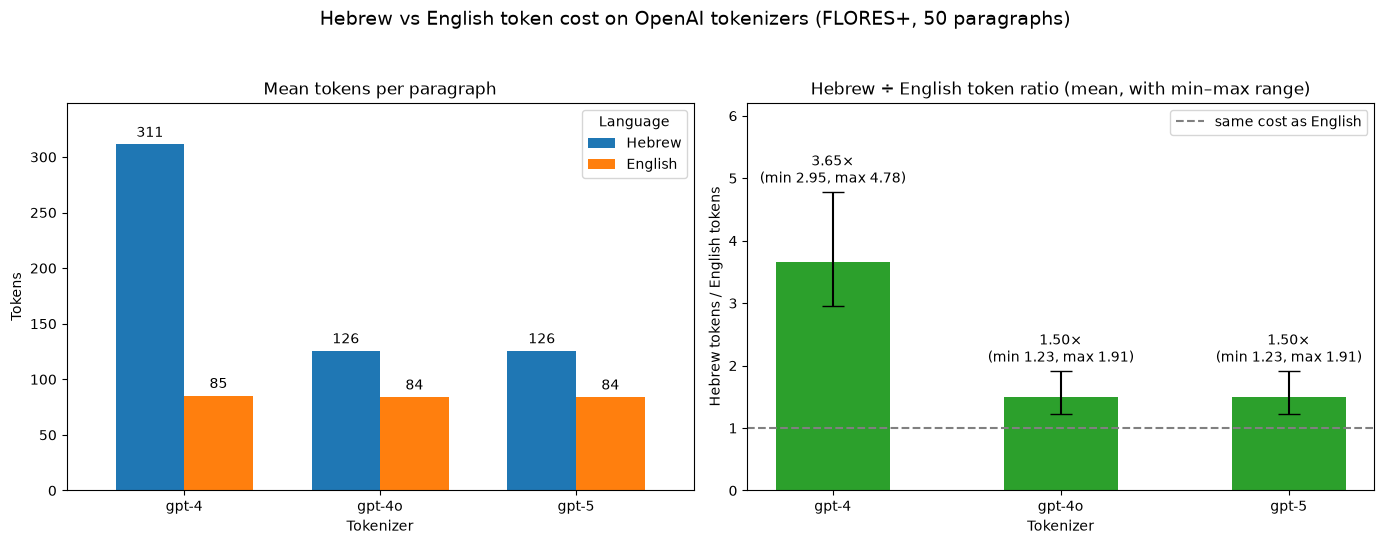

In [8]:
tokens = (
    results.groupby("counter")[["he_tokens", "en_tokens"]]
    .mean()
    .rename(columns={"he_tokens": "Hebrew", "en_tokens": "English"})
)
n_paragraphs = results["pair_id"].nunique()

fig, (ax_tokens, ax_ratio) = plt.subplots(1, 2, figsize=(14, 5.5))

tokens.plot.bar(ax=ax_tokens, rot=0, width=0.7)
for container in ax_tokens.containers:
    ax_tokens.bar_label(container, fmt="%.0f", padding=3)
ax_tokens.set_title("Mean tokens per paragraph")
ax_tokens.set_xlabel("Tokenizer")
ax_tokens.set_ylabel("Tokens")
ax_tokens.set_ylim(0, tokens.max().max() * 1.12)
ax_tokens.legend(title="Language")

ax_ratio.bar(
    summary.index,
    summary["mean_ratio"],
    yerr=[
        summary["mean_ratio"] - summary["min_ratio"],
        summary["max_ratio"] - summary["mean_ratio"],
    ],
    capsize=8,
    color="tab:green",
    width=0.5,
)
for position, (mean, low, high) in enumerate(
    zip(summary["mean_ratio"], summary["min_ratio"], summary["max_ratio"])
):
    ax_ratio.text(
        position,
        high + 0.08,
        f"{mean:.2f}×\n(min {low:.2f}, max {high:.2f})",
        ha="center",
        va="bottom",
    )
ax_ratio.axhline(1.0, linestyle="--", color="gray", label="same cost as English")
ax_ratio.set_title("Hebrew ÷ English token ratio (mean, with min–max range)")
ax_ratio.set_xlabel("Tokenizer")
ax_ratio.set_ylabel("Hebrew tokens / English tokens")
ax_ratio.set_ylim(0, summary["max_ratio"].max() * 1.3)
ax_ratio.legend()

fig.suptitle(
    f"Hebrew vs English token cost on OpenAI tokenizers "
    f"(FLORES+, {n_paragraphs} paragraphs)",
    fontsize=14,
)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(os.path.join(RESULTS_DIR, "01_tokenizer_ratios.png"), dpi=150)
plt.show()

## 9. Findings